# CellVOCAL direction-recovery tutorial

This notebook follows the simulation experiment described in the Methods: CellVOCAL learns RNA velocity and ligand-receptor influence from four prepared spatial AnnData inputs with increasingly complex developmental geometry. The datasets are handled in sequence so that training, quantitative assessment, and visualization for one geometry are completed before the next begins.

> Start Jupyter from the repository root. The expensive `run_cellvocal` calls are commented by default; the analysis cells reuse the fitted `out.h5ad` files.

## Shared model settings

All four simulations use the same graph and optimization settings. Ninety spatial neighbors define candidate senders, while at most 72 communication events are retained per receiver. RNA maturity supplies the temporal prior because the benchmark inputs contain simulated spliced and unspliced counts.

Spatial velocity maps use the Ext. Fig. 1a rendering: a 17 × 17 grid, at least six cells per bin, and equal-length arrows after averaging cell velocities. Arrows encode direction, not speed. Up to 2,200 background cells are sampled spatially; pseudotime uses full-range 0–1 normalization. Each image row shows inferred time, velocity colored by pseudotime, and velocity colored by cell type.

In [1]:
from base64 import b64encode
from copy import deepcopy
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "model").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from IPython.utils.capture import capture_output

from model.train.config import CellVOCALConfig
from pipeline.analysis import CellVOCALAnalysis
from pipeline.cellvocal import run_cellvocal
from utils.metric.velocity import VelocityEvaluator


def display_image_row(paths):
    image_tiles = []
    for path in paths:
        encoded = b64encode(Path(path).read_bytes()).decode("ascii")
        image_tiles.append(
            f'<img src="data:image/png;base64,{encoded}" alt="{Path(path).stem}" '
            'style="flex:1 1 0;min-width:0;width:32%;height:auto;object-fit:contain">'
        )
    display(HTML('<div style="display:flex;flex-wrap:nowrap;gap:8px;align-items:flex-start;width:100%">' + "".join(image_tiles) + "</div>"))


# Shared cell-type colors from Ext. Fig. 1a, independent of dataset row order.
CELL_TYPE_COLORS = {
    "early_region_0": "#007C83",
    "transition_region_0": "#E69F00",
    "transition_region_1": "#4E79A7",
    "late_region_1": "#59A14F",
    "late_region_3": "#CC79A7",
    "early_region_1": "#D55E4F",
    "transition_region_3": "#9467BD",
    "transition_region_2": "#8C564B",
    "late_region_2": "#17BECF",
    "early_region_2": "#BCBD22",
    "early_region_3": "#F28E2B",
    "late_region_0": "#76B7B2",
}


In [2]:
DATA_ROOT = ROOT / "paper" / "data" / "direction"

torch.manual_seed(2022)
np.random.seed(2022)

BASE_CONFIG = CellVOCALConfig()
BASE_CONFIG.train.device = "cuda:0" if torch.cuda.is_available() else "cpu"
BASE_CONFIG.qc.normalize_per_spot = False
BASE_CONFIG.graph.ccc_ligand_expr_quantile = 0.0
BASE_CONFIG.graph.ccc_receptor_expr_quantile = 0.0
BASE_CONFIG.graph.n_spatial_neighbors = 90
BASE_CONFIG.graph.ccc_event_budget_per_receiver = 72
BASE_CONFIG.model.use_cell_annotation = False
BASE_CONFIG.model.rho_modulation_strength = 0.35
BASE_CONFIG.model.ccc_velocity_scale = 0.4
BASE_CONFIG.train.velocity_target_unspliced_layer = None
BASE_CONFIG.train.velocity_target_spliced_layer = None
BASE_CONFIG.train.time_prior_source = "rna_maturity"
BASE_CONFIG.train.time_prior_smoothing_steps = 4
BASE_CONFIG.train.w_time = 0.5

## 1. Linear trajectory

The linear simulation is the simplest identifiability test: the inferred latent time and spatial velocity should follow a single developmental axis. The LR prior is read from the simulation ground truth only to specify which ligand-receptor modules are admissible during training.

In [3]:
linear_cfg = deepcopy(BASE_CONFIG)
linear_cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / "linear" / "checkpoints"
linear_cfg.eval.output_dir = DATA_ROOT / "cellvocal" / "linear" / "results"

# linear_input = ad.read_h5ad(DATA_ROOT / "raw" / "linear.h5ad")
# linear_edges = np.linspace(linear_input.obs["true_time"].min(), linear_input.obs["true_time"].max(), 6)
# linear_input.obs["clusters"] = np.digitize(linear_input.obs["true_time"], linear_edges[1:-1]).astype(str)
# linear_lr = linear_input.uns["ground_truth"]["lr_pairs"]
# linear_lr_pairs = [{"interaction": f"{lig}_{rec}", "pathway": str(mod), "module_id": str(mod), "ligand": str(lig), "receptor": str(rec), "ligand_genes": [str(lig)], "receptor_genes": [str(rec)]} for lig, rec, mod in zip(linear_lr["ligand_gene"], linear_lr["receptor_gene"], linear_lr["module_id"])]
# linear_result = run_cellvocal(linear_input, config=linear_cfg, lr_pairs=linear_lr_pairs)

,Dataset,linear
Metrics,Model,
Time Correlation,CellVOCAL,0.964
Spatial Velocity Consistency,CellVOCAL,0.973
Spatial Time Consistency,CellVOCAL,0.995
CBDir,CellVOCAL,0.836



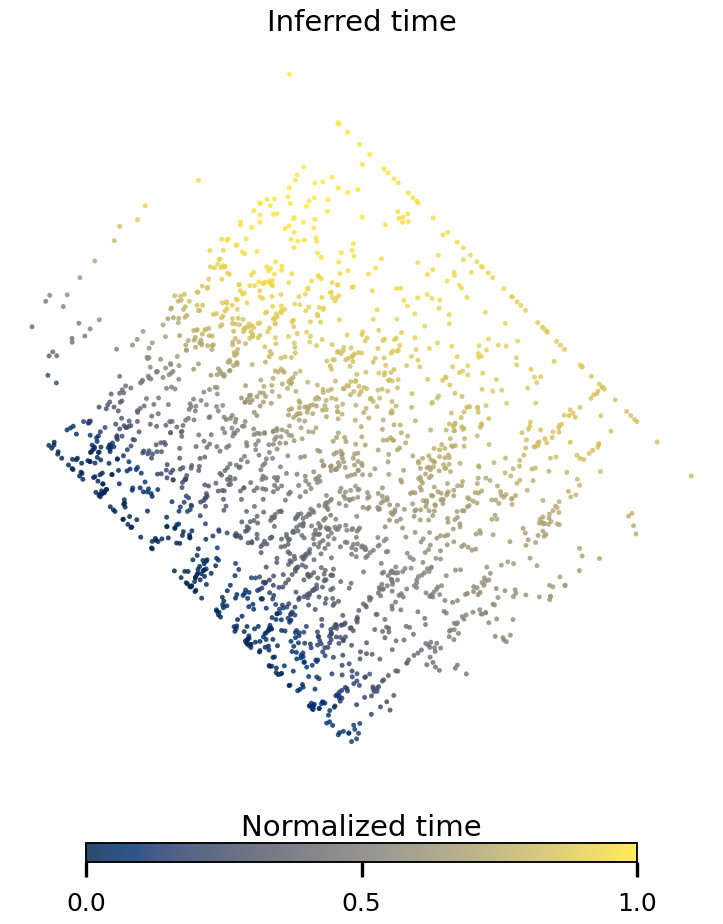
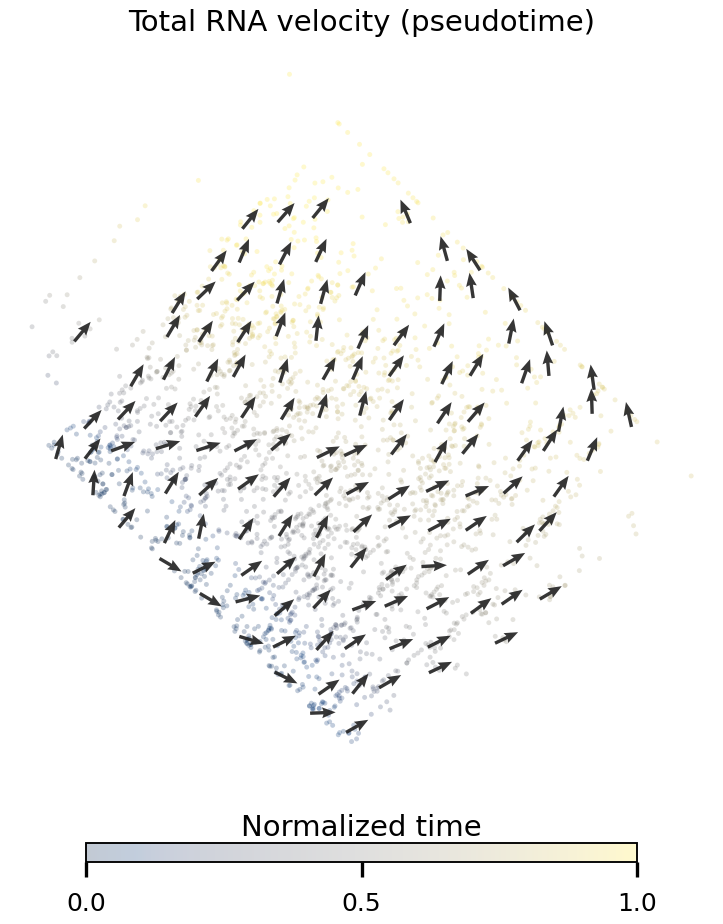
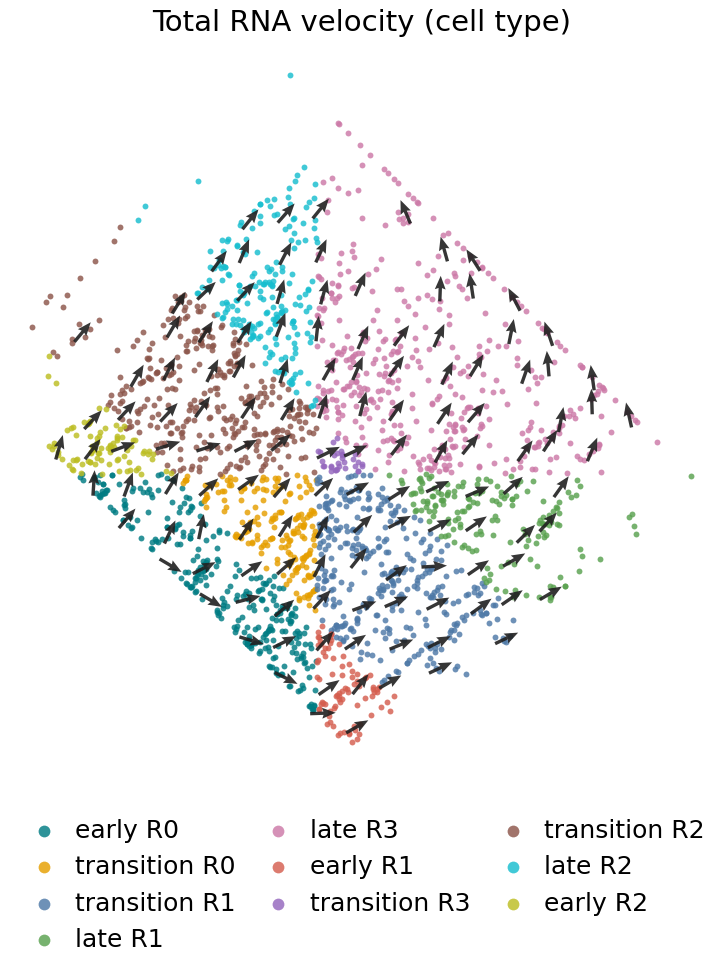

In [4]:
linear_analysis = CellVOCALAnalysis.from_h5ad(linear_cfg.eval.output_dir / "out.h5ad", config=linear_cfg)
with capture_output():
    linear_metrics = linear_analysis.evaluate_metrics(cluster_edges=VelocityEvaluator.chain_edges(5), tprior_key="true_time", dataset_name="linear", seed=linear_cfg.eval.seed, n_jobs=linear_cfg.eval.benchmark_n_jobs)
    linear_plots = linear_analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / "linear" / "velocity", cluster_key="cell_type", seed=2022, palette=CELL_TYPE_COLORS)
display(linear_metrics)
display_image_row(linear_plots)

## 2. Bidirectional trajectory

The bidirectional input tests whether a shared kinetic model can recover opposing spatial flows. It is trained and evaluated independently from the linear result so that neither fitted parameters nor graph structure are transferred between geometries.

In [5]:
bilinear_cfg = deepcopy(BASE_CONFIG)
bilinear_cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / "bilinear" / "checkpoints"
bilinear_cfg.eval.output_dir = DATA_ROOT / "cellvocal" / "bilinear" / "results"

# bilinear_input = ad.read_h5ad(DATA_ROOT / "raw" / "bilinear.h5ad")
# bilinear_edges = np.linspace(bilinear_input.obs["true_time"].min(), bilinear_input.obs["true_time"].max(), 6)
# bilinear_input.obs["clusters"] = np.digitize(bilinear_input.obs["true_time"], bilinear_edges[1:-1]).astype(str)
# bilinear_lr = bilinear_input.uns["ground_truth"]["lr_pairs"]
# bilinear_lr_pairs = [{"interaction": f"{lig}_{rec}", "pathway": str(mod), "module_id": str(mod), "ligand": str(lig), "receptor": str(rec), "ligand_genes": [str(lig)], "receptor_genes": [str(rec)]} for lig, rec, mod in zip(bilinear_lr["ligand_gene"], bilinear_lr["receptor_gene"], bilinear_lr["module_id"])]
# bilinear_result = run_cellvocal(bilinear_input, config=bilinear_cfg, lr_pairs=bilinear_lr_pairs)

,Dataset,bilinear
Metrics,Model,
Time Correlation,CellVOCAL,0.993
Spatial Velocity Consistency,CellVOCAL,0.964
Spatial Time Consistency,CellVOCAL,0.996
CBDir,CellVOCAL,0.835



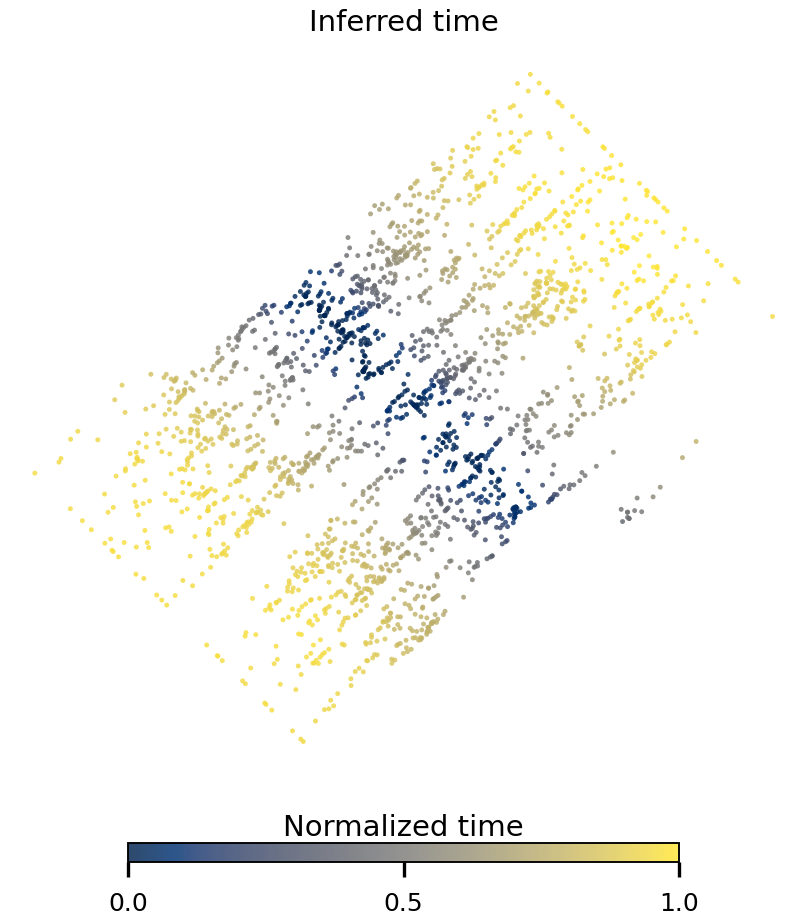
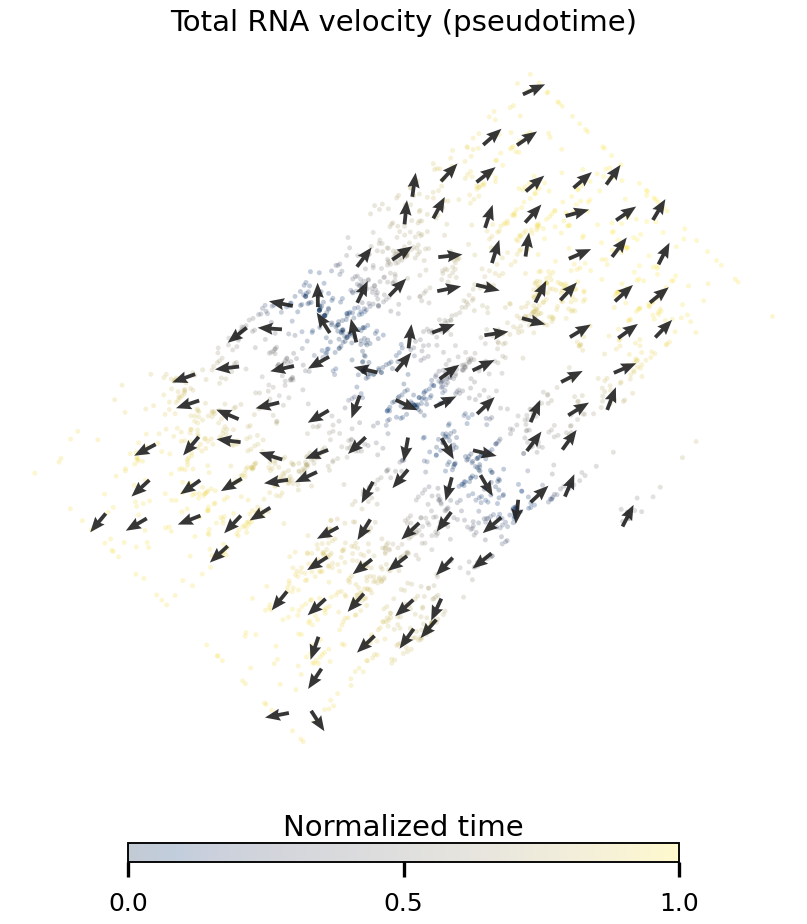
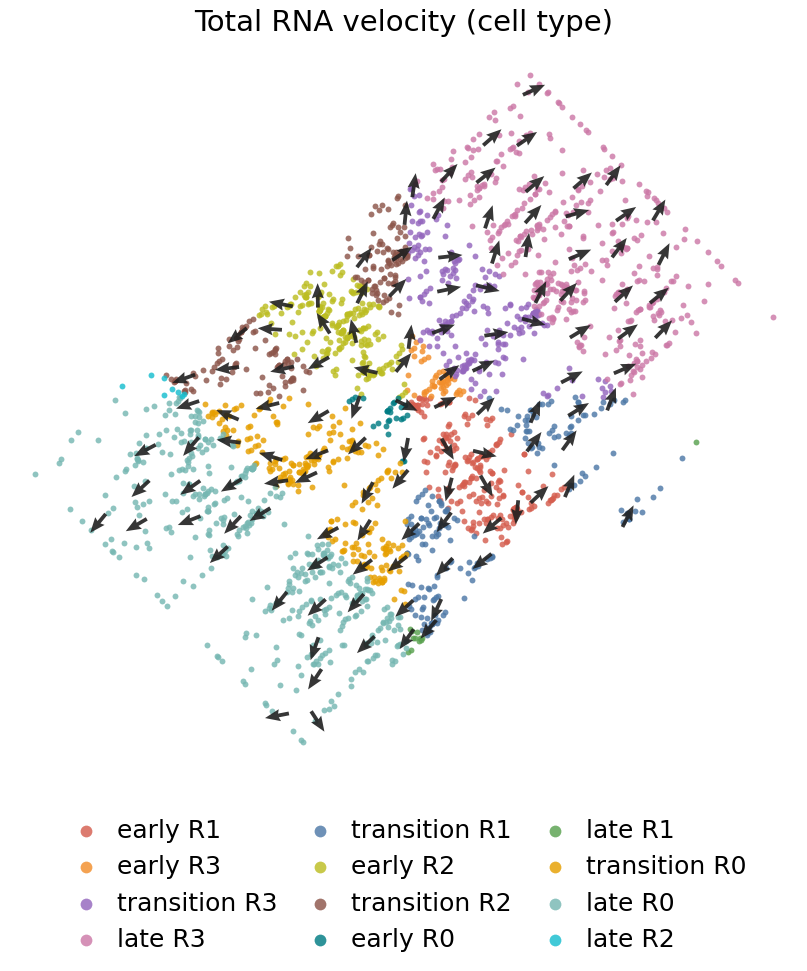

In [6]:
bilinear_analysis = CellVOCALAnalysis.from_h5ad(bilinear_cfg.eval.output_dir / "out.h5ad", config=bilinear_cfg)
with capture_output():
    bilinear_metrics = bilinear_analysis.evaluate_metrics(cluster_edges=VelocityEvaluator.chain_edges(5), tprior_key="true_time", dataset_name="bilinear", seed=bilinear_cfg.eval.seed, n_jobs=bilinear_cfg.eval.benchmark_n_jobs)
    bilinear_plots = bilinear_analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / "bilinear" / "velocity", cluster_key="cell_type", seed=2023, palette=CELL_TYPE_COLORS)
display(bilinear_metrics)
display_image_row(bilinear_plots)

## 3. Radial trajectory

The radial geometry replaces a Cartesian developmental axis with outward progression from a single center. Correct recovery requires the spatial embedding of the learned transcriptomic velocity to rotate continuously around the origin.

In [7]:
radial_cfg = deepcopy(BASE_CONFIG)
radial_cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / "radial" / "checkpoints"
radial_cfg.eval.output_dir = DATA_ROOT / "cellvocal" / "radial" / "results"

# radial_input = ad.read_h5ad(DATA_ROOT / "raw" / "radial.h5ad")
# radial_edges = np.linspace(radial_input.obs["true_time"].min(), radial_input.obs["true_time"].max(), 6)
# radial_input.obs["clusters"] = np.digitize(radial_input.obs["true_time"], radial_edges[1:-1]).astype(str)
# radial_lr = radial_input.uns["ground_truth"]["lr_pairs"]
# radial_lr_pairs = [{"interaction": f"{lig}_{rec}", "pathway": str(mod), "module_id": str(mod), "ligand": str(lig), "receptor": str(rec), "ligand_genes": [str(lig)], "receptor_genes": [str(rec)]} for lig, rec, mod in zip(radial_lr["ligand_gene"], radial_lr["receptor_gene"], radial_lr["module_id"])]
# radial_result = run_cellvocal(radial_input, config=radial_cfg, lr_pairs=radial_lr_pairs)

,Dataset,radial
Metrics,Model,
Time Correlation,CellVOCAL,0.961
Spatial Velocity Consistency,CellVOCAL,0.970
Spatial Time Consistency,CellVOCAL,0.982
CBDir,CellVOCAL,0.634



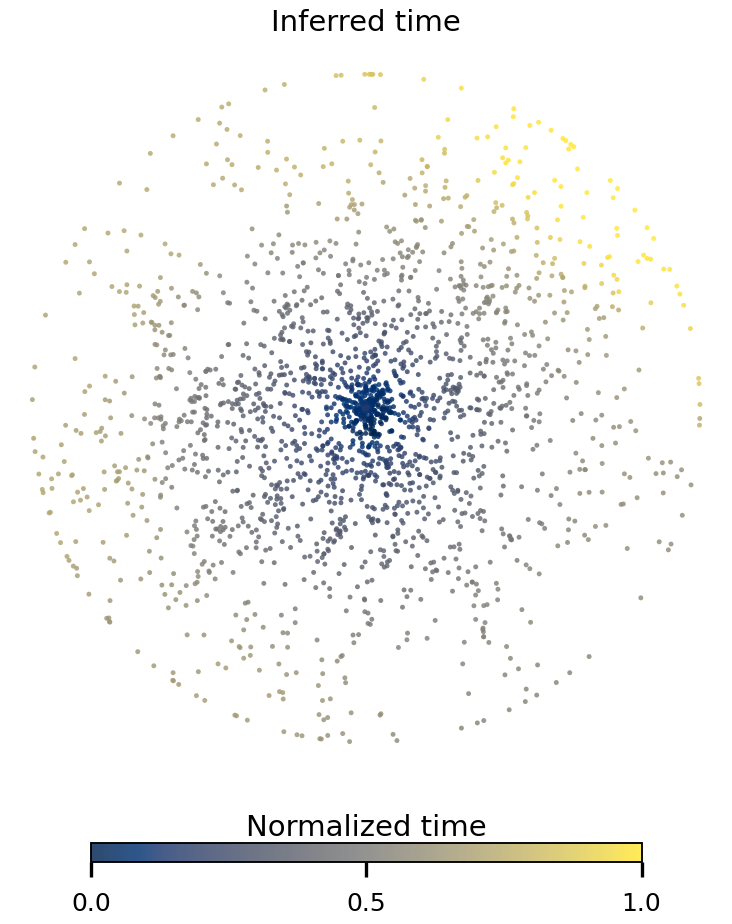
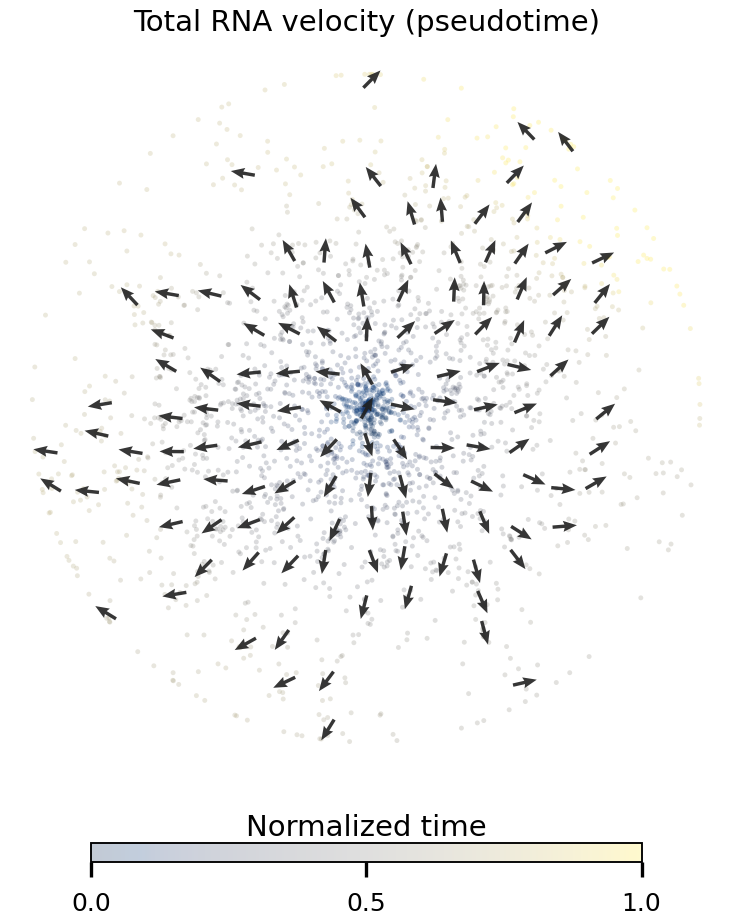
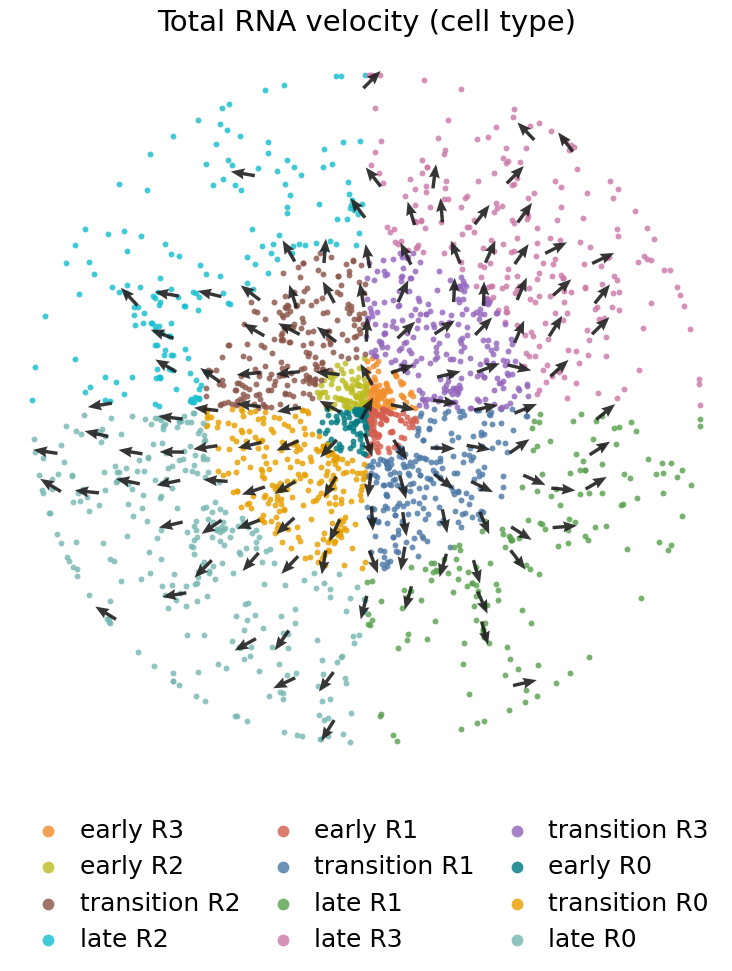

In [8]:
radial_analysis = CellVOCALAnalysis.from_h5ad(radial_cfg.eval.output_dir / "out.h5ad", config=radial_cfg)
with capture_output():
    radial_metrics = radial_analysis.evaluate_metrics(cluster_edges=VelocityEvaluator.chain_edges(5), tprior_key="true_time", dataset_name="radial", seed=radial_cfg.eval.seed, n_jobs=radial_cfg.eval.benchmark_n_jobs)
    radial_plots = radial_analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / "radial" / "velocity", cluster_key="cell_type", seed=2024, palette=CELL_TYPE_COLORS)
display(radial_metrics)
display_image_row(radial_plots)

## 4. Multi-radial trajectory

The final benchmark combines four radial systems in one AnnData object. It tests whether CellVOCAL preserves locally correct directions when the tissue contains several independent developmental centers.

In [9]:
multiradial_cfg = deepcopy(BASE_CONFIG)
multiradial_cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / "multiradial" / "checkpoints"
multiradial_cfg.eval.output_dir = DATA_ROOT / "cellvocal" / "multiradial" / "results"

# multiradial_input = ad.read_h5ad(DATA_ROOT / "raw" / "multiradial.h5ad")
# multiradial_edges = np.linspace(multiradial_input.obs["true_time"].min(), multiradial_input.obs["true_time"].max(), 6)
# multiradial_input.obs["clusters"] = np.digitize(multiradial_input.obs["true_time"], multiradial_edges[1:-1]).astype(str)
# multiradial_lr = multiradial_input.uns["ground_truth"]["lr_pairs"]
# multiradial_lr_pairs = [{"interaction": f"{lig}_{rec}", "pathway": str(mod), "module_id": str(mod), "ligand": str(lig), "receptor": str(rec), "ligand_genes": [str(lig)], "receptor_genes": [str(rec)]} for lig, rec, mod in zip(multiradial_lr["ligand_gene"], multiradial_lr["receptor_gene"], multiradial_lr["module_id"])]
# multiradial_result = run_cellvocal(multiradial_input, config=multiradial_cfg, lr_pairs=multiradial_lr_pairs)

,Dataset,multiradial
Metrics,Model,
Time Correlation,CellVOCAL,0.951
Spatial Velocity Consistency,CellVOCAL,0.896
Spatial Time Consistency,CellVOCAL,0.989
CBDir,CellVOCAL,0.664



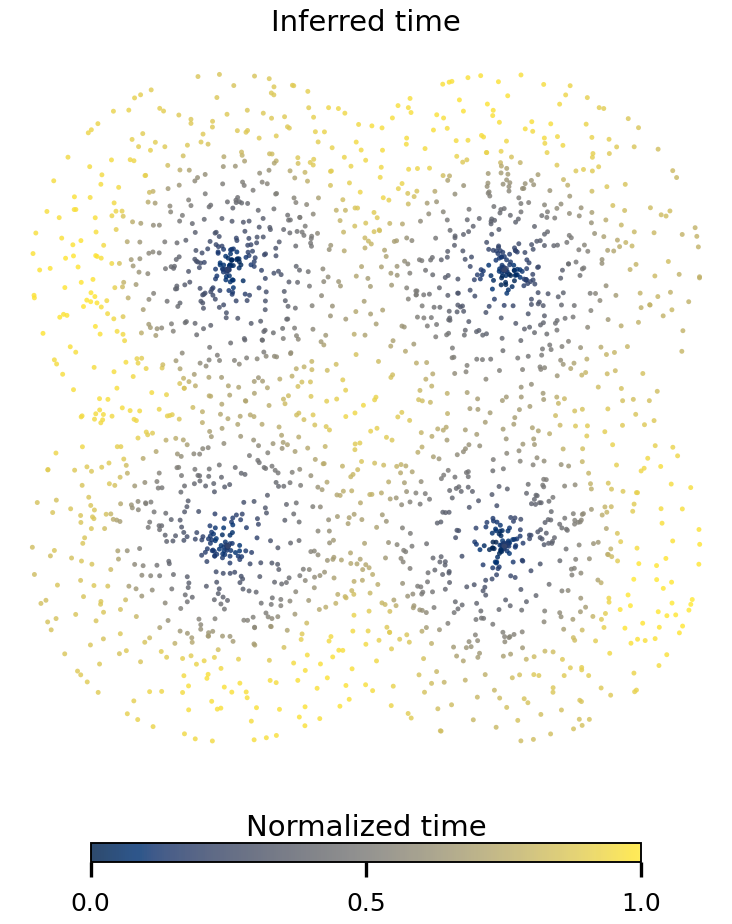
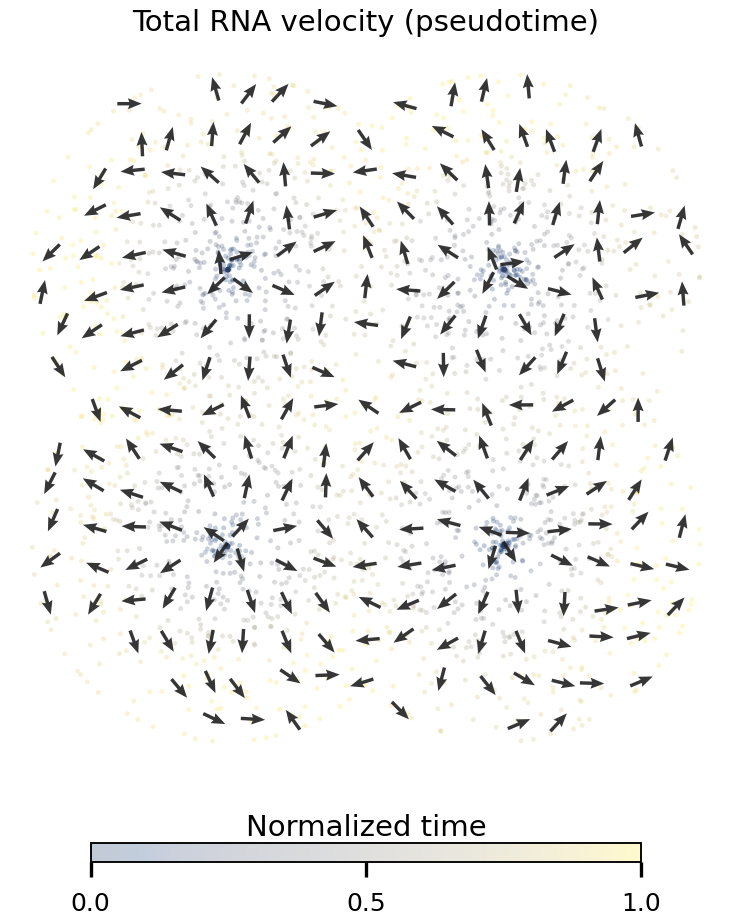
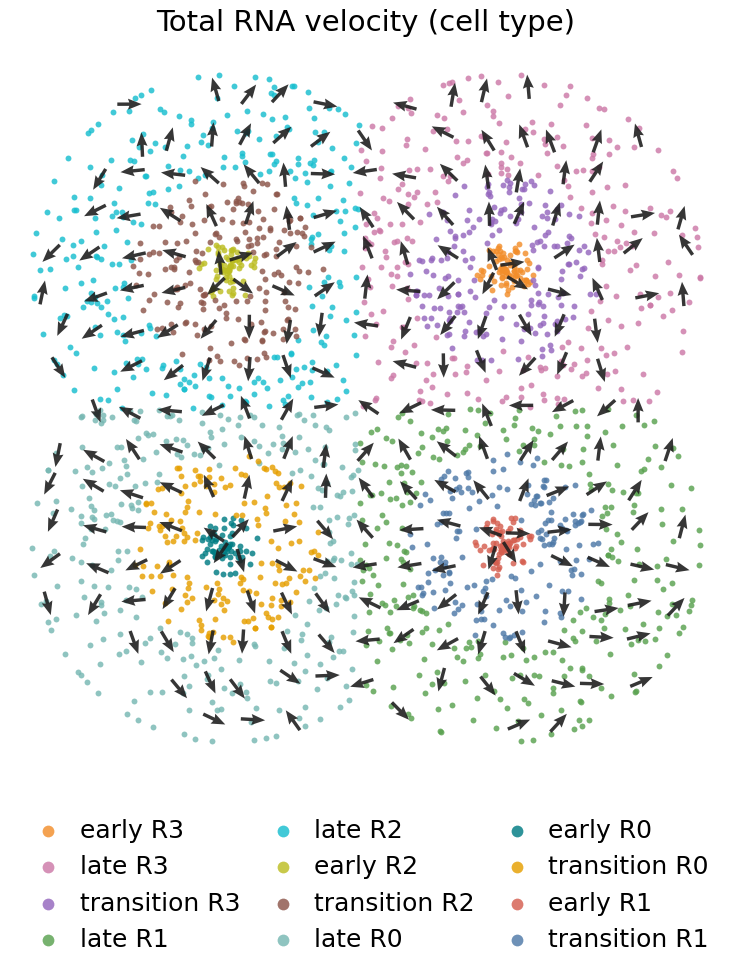

In [10]:
multiradial_analysis = CellVOCALAnalysis.from_h5ad(multiradial_cfg.eval.output_dir / "out.h5ad", config=multiradial_cfg)
with capture_output():
    multiradial_metrics = multiradial_analysis.evaluate_metrics(cluster_edges=VelocityEvaluator.chain_edges(5), tprior_key="true_time", dataset_name="multiradial", seed=multiradial_cfg.eval.seed, n_jobs=multiradial_cfg.eval.benchmark_n_jobs)
    multiradial_plots = multiradial_analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / "multiradial" / "velocity", cluster_key="cell_type", seed=2025, palette=CELL_TYPE_COLORS)
display(multiradial_metrics)
display_image_row(multiradial_plots)

## Cross-geometry comparison

The final table puts all four recovery tests on one scale. Time correlation checks ordering, the two spatial consistencies check smoothness/alignment, and CBDir is the most direct cluster-transition score. The radial cases are intentionally harder than the linear cases.

In [ ]:
direction_summary = pd.DataFrame({
    "linear": linear_metrics.iloc[:, -1],
    "bilinear": bilinear_metrics.iloc[:, -1],
    "radial": radial_metrics.iloc[:, -1],
    "multiradial": multiradial_metrics.iloc[:, -1],
}).T
direction_summary.index.name = "geometry"
display(direction_summary.round(3))

,Time Correlation,Spatial Velocity Consistency,Spatial Time Consistency,CBDir
geometry,,,,
linear,0.964,0.973,0.995,0.836
bilinear,0.993,0.964,0.996,0.835
radial,0.961,0.970,0.982,0.634
multiradial,0.951,0.896,0.989,0.664


## Interpretation

The linear and bidirectional systems recover the strongest cluster-level direction (CBDir ≈ 0.84). Radial and multi-radial geometries retain high time/spatial consistency but lower CBDir, exposing the added difficulty of locally varying directions. Read each metric row together with its own three-panel image row above.